In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

**Warning!** I'm hacking the sqrt behavior of pint.  Consider using the jmfranck/pint fork


First, we load our files, and just see what the data looks like

In [2]:
# Cycle 1
# d1 = find_file("241205_TS_dodec_W20_11mM_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
# d2 = find_file("241205_TS_dodec_W20_11mM_run2.DSC", exp_type="francklab_esr/romana") # heating 1 subsequently --after cooling and heating

# Cycle 2
# d1 = find_file("241205_TS_dodec_W20_11mM_run3.DSC", exp_type="francklab_esr/romana") # cooling 2 --initial sample
# d2 = find_file("241205_TS_dodec_W20_11mM_run4.DSC", exp_type="francklab_esr/romana") # heating 2 subsequently --after cooling and heating

#below transition
d1 = find_file("241205_TS_dodec_W20_11mM_run5.DSC", exp_type="francklab_esr/romana") # cooling 3 --initial sample
d2 = find_file("241205_TS_dodec_W20_11mM_run6.DSC", exp_type="francklab_esr/romana") # heating 3 subsequently --after cooling and heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (42, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (42, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (42, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (42, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'cooling1')

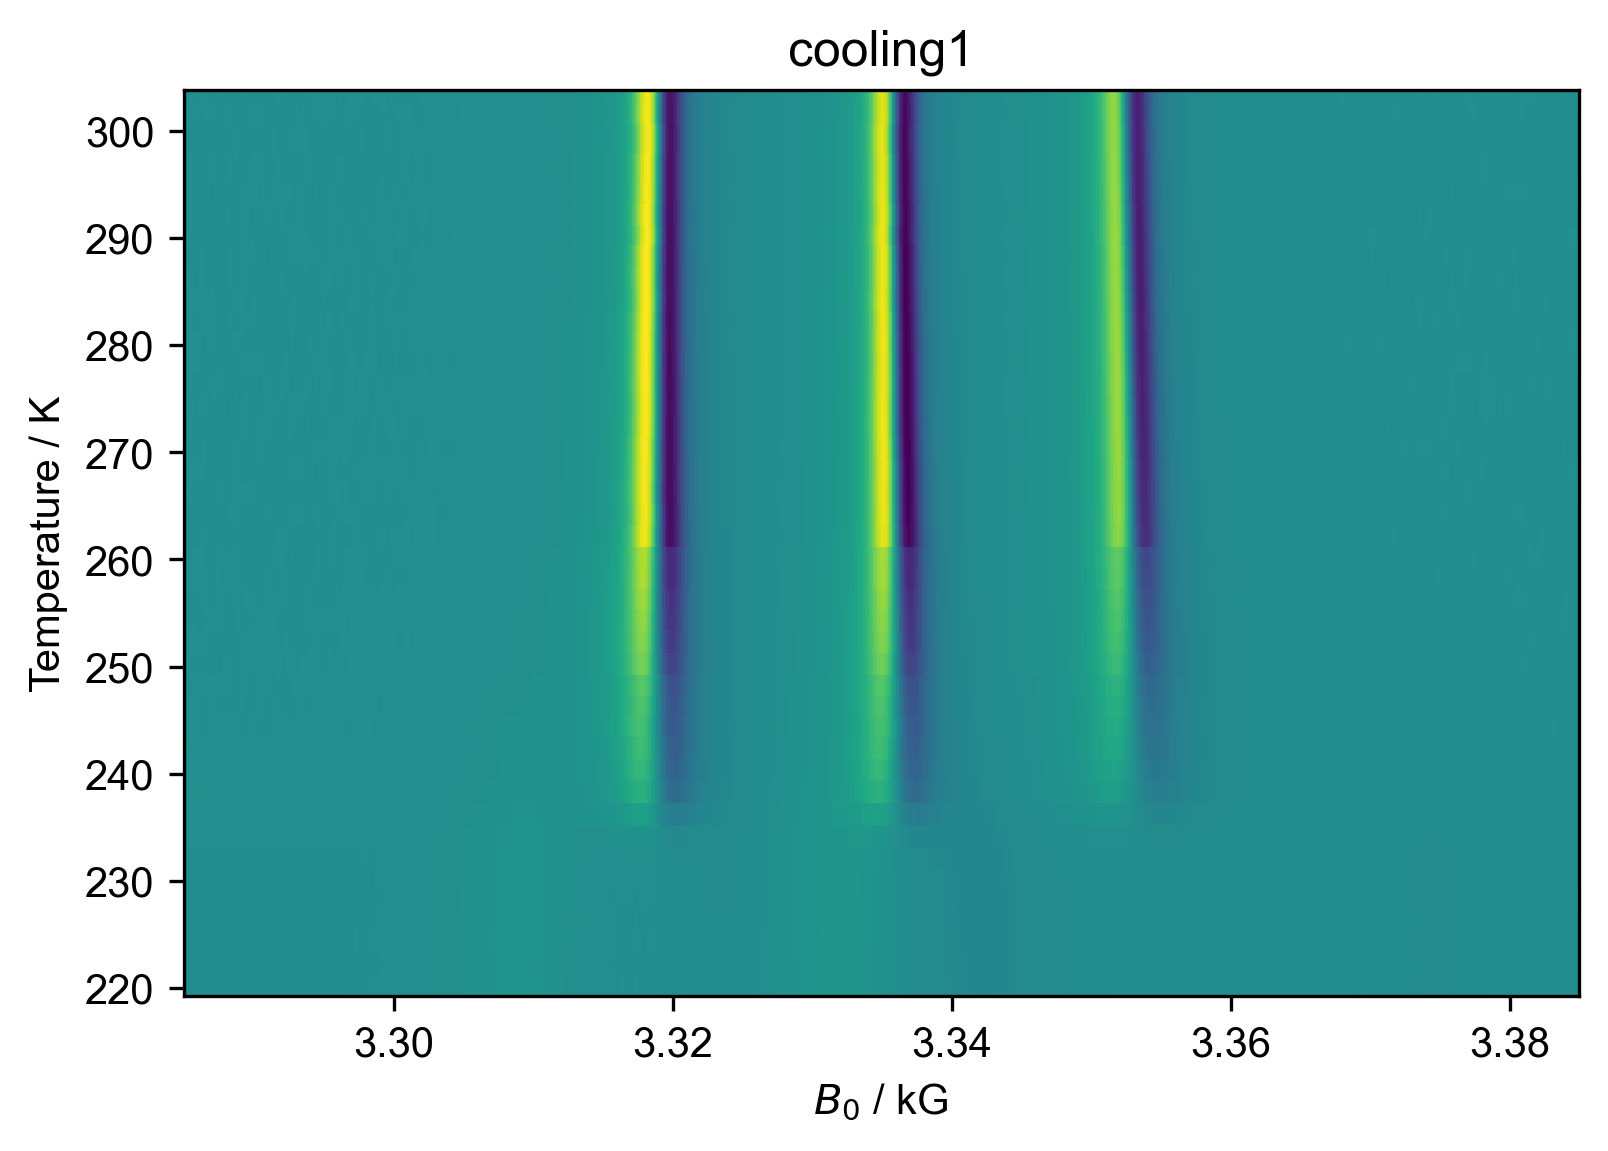

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("cooling1")

Text(0.5, 1.0, 'heating1')

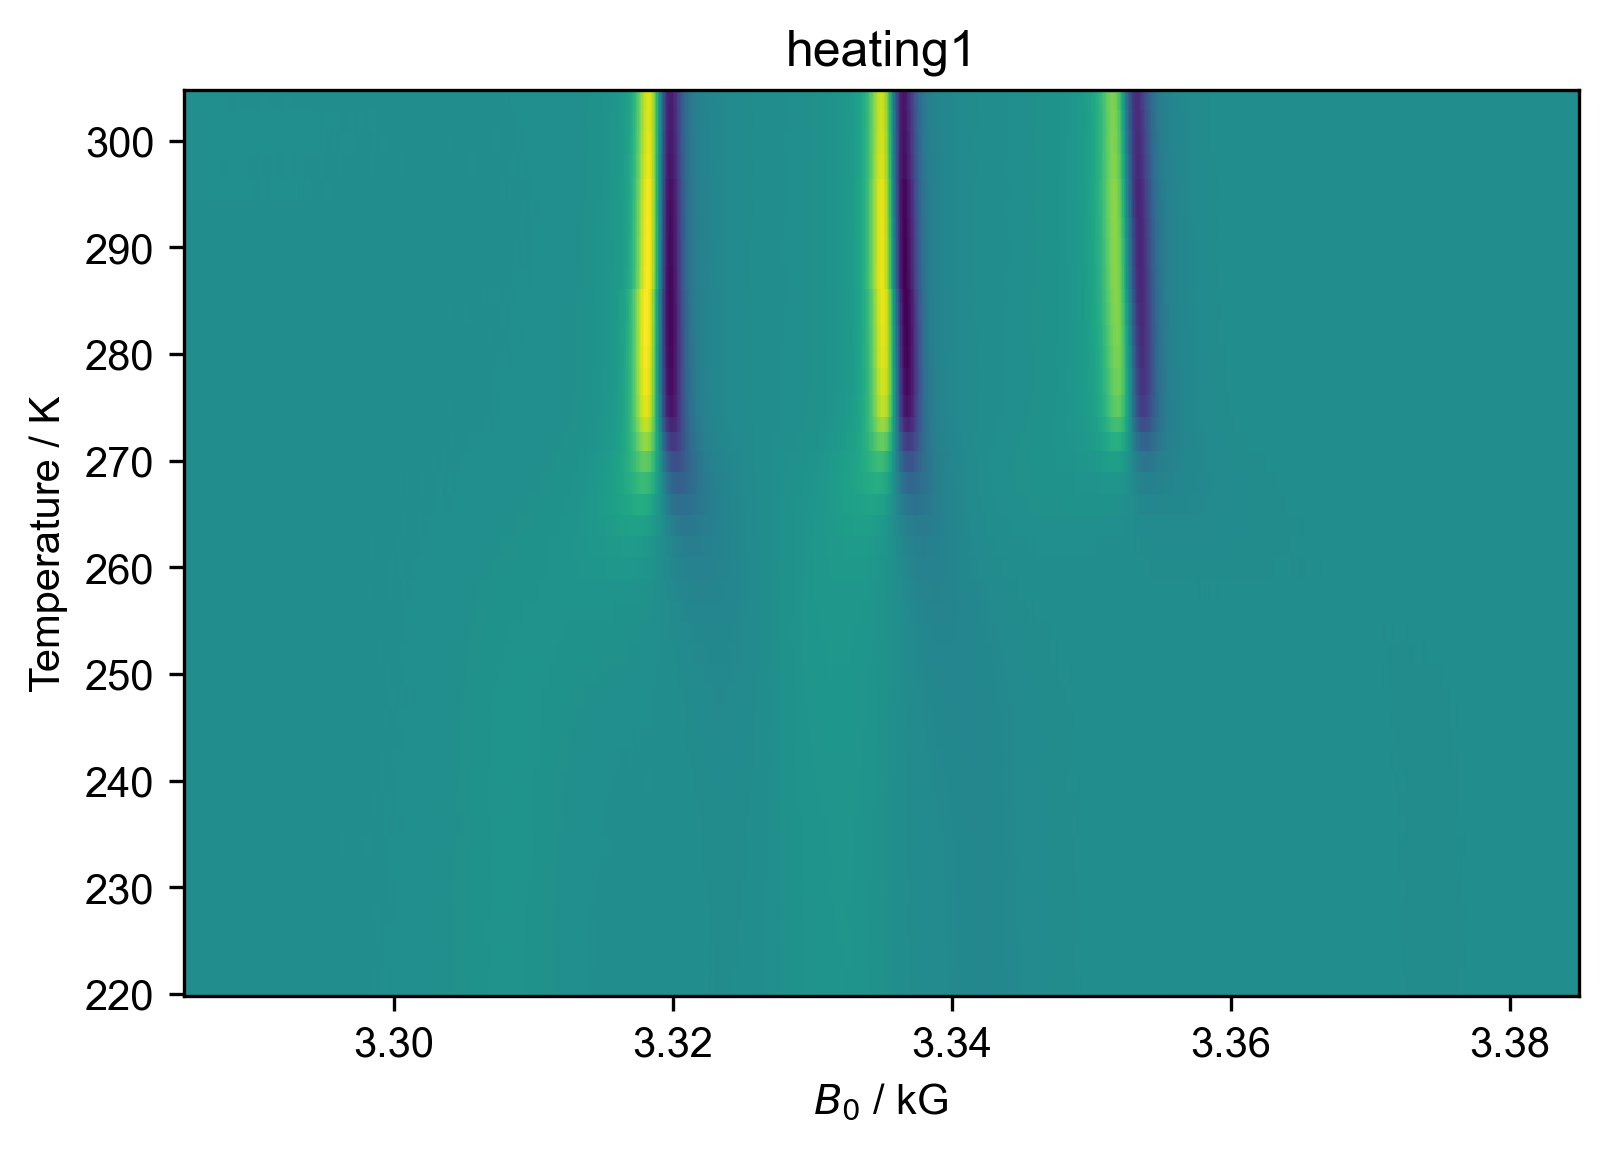

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("heating1")

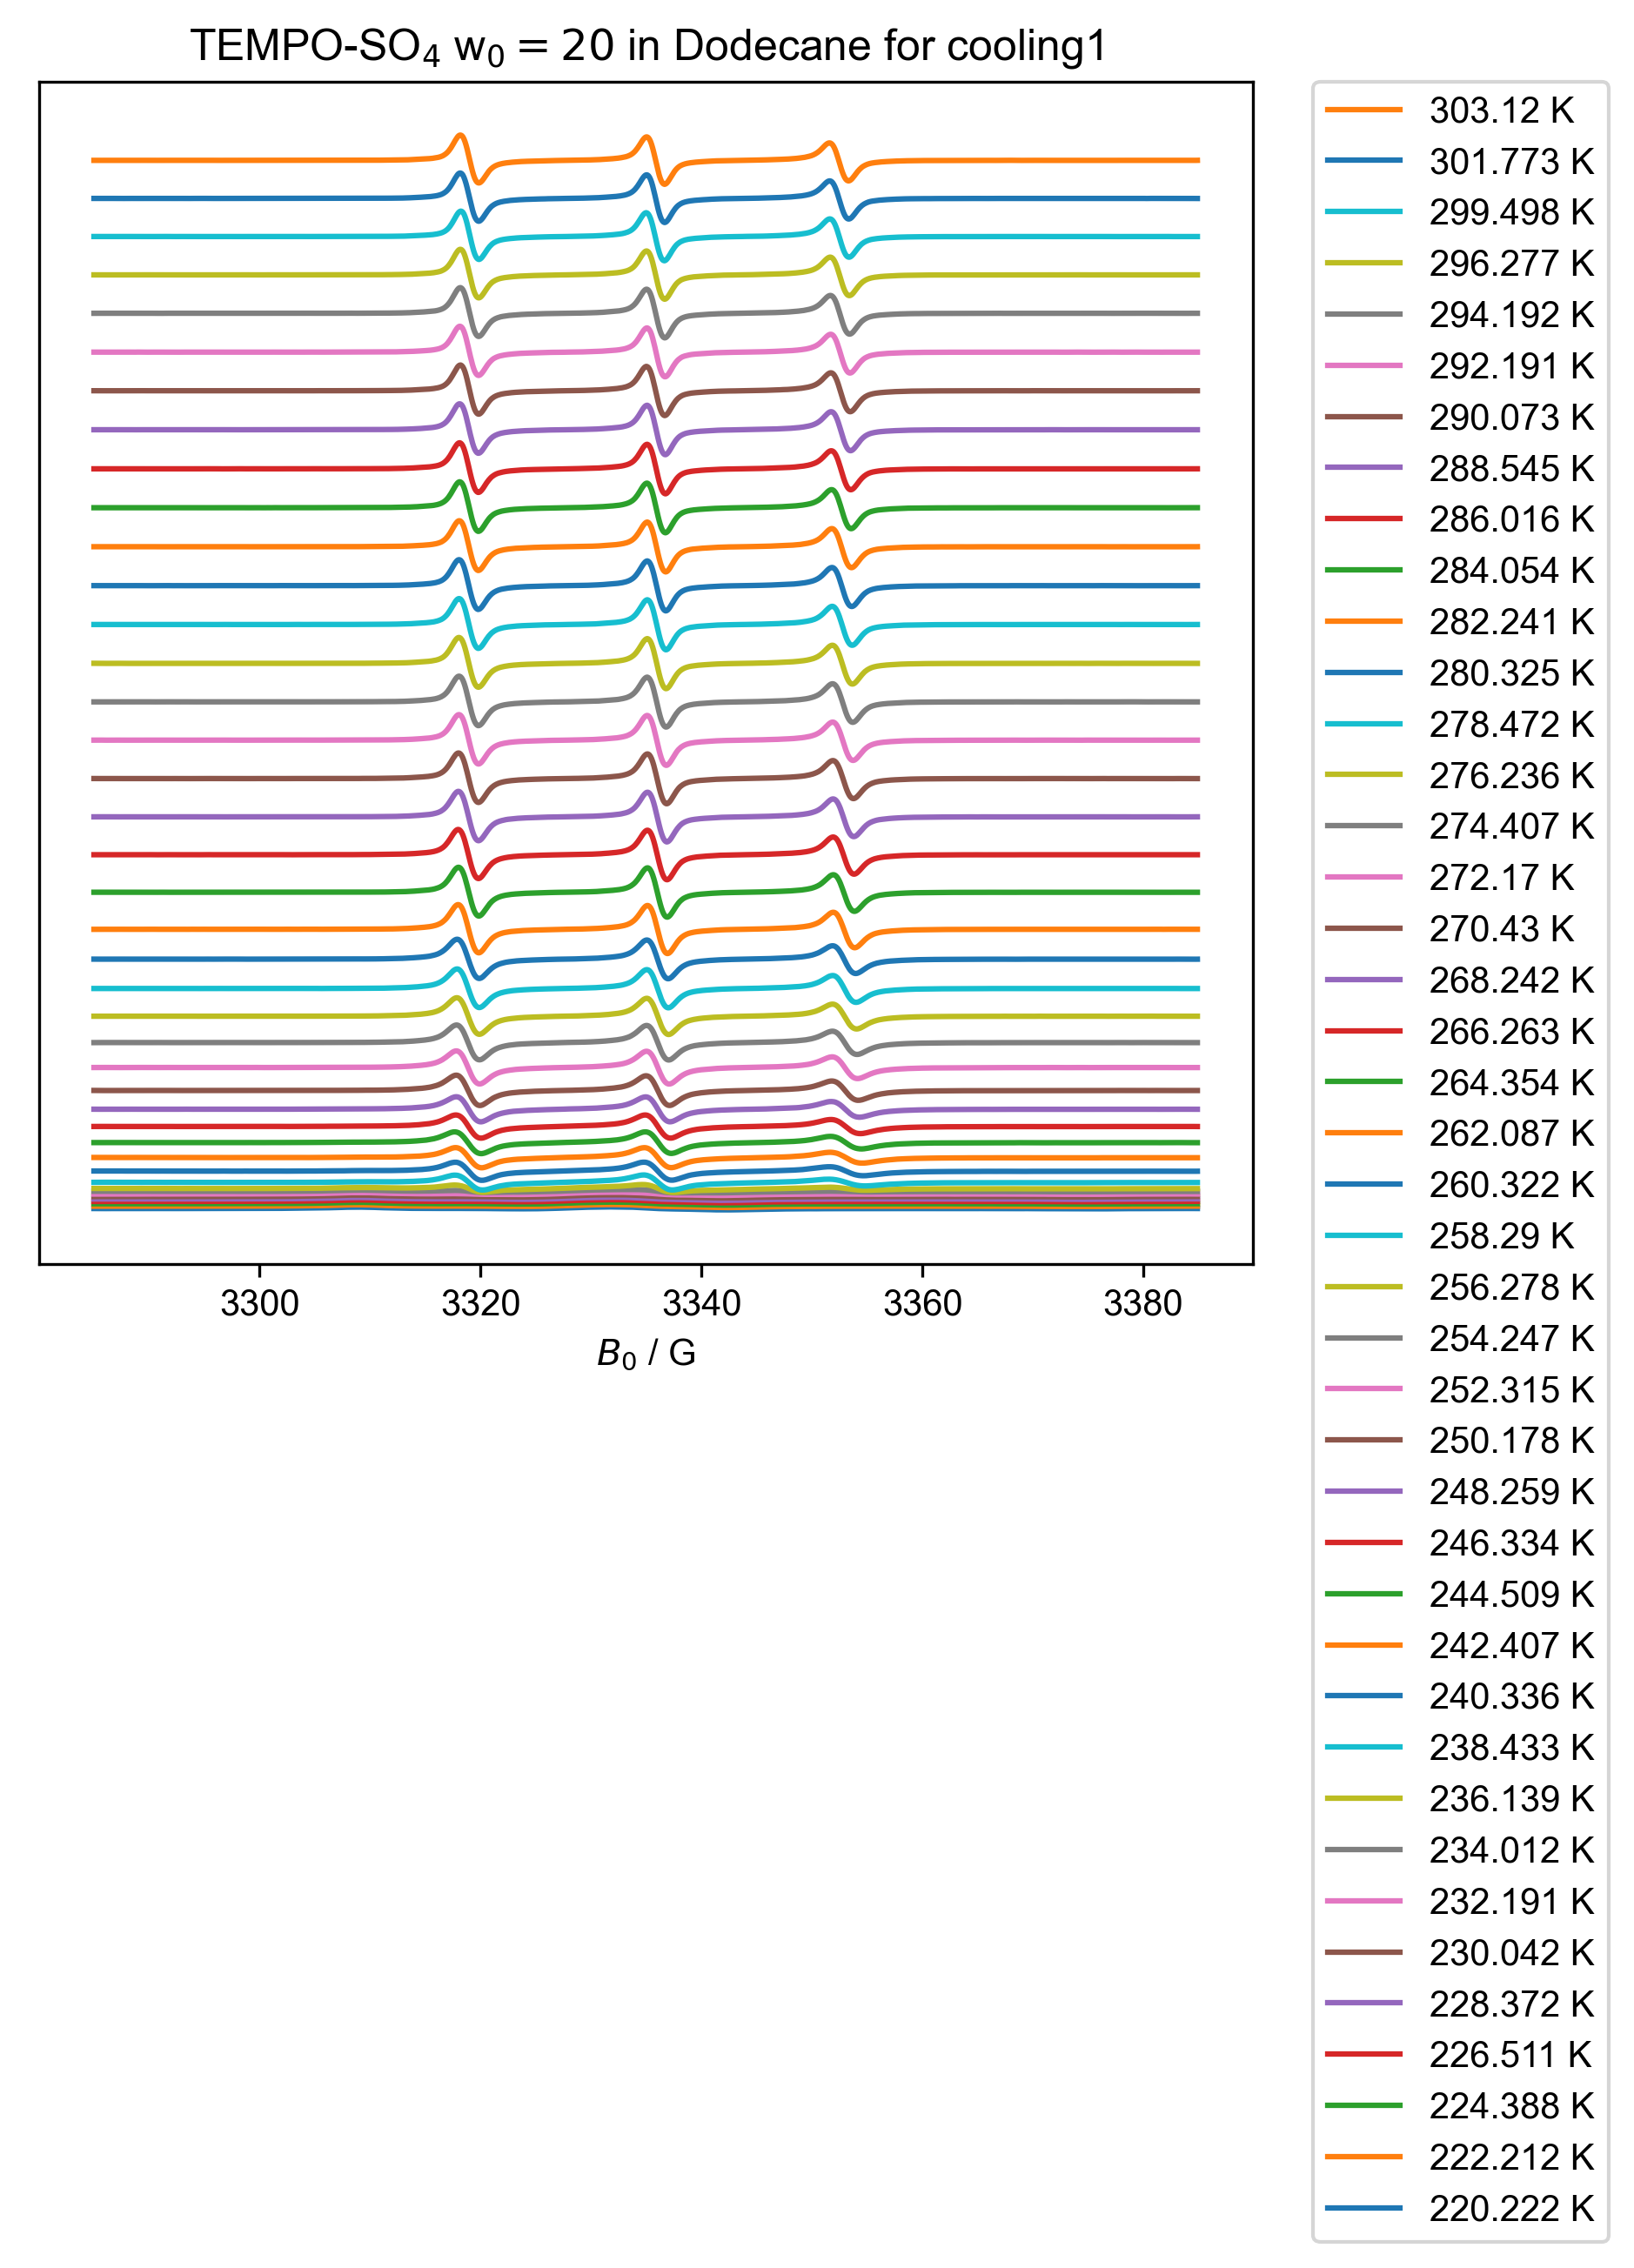

In [11]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling1", (200, 350))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

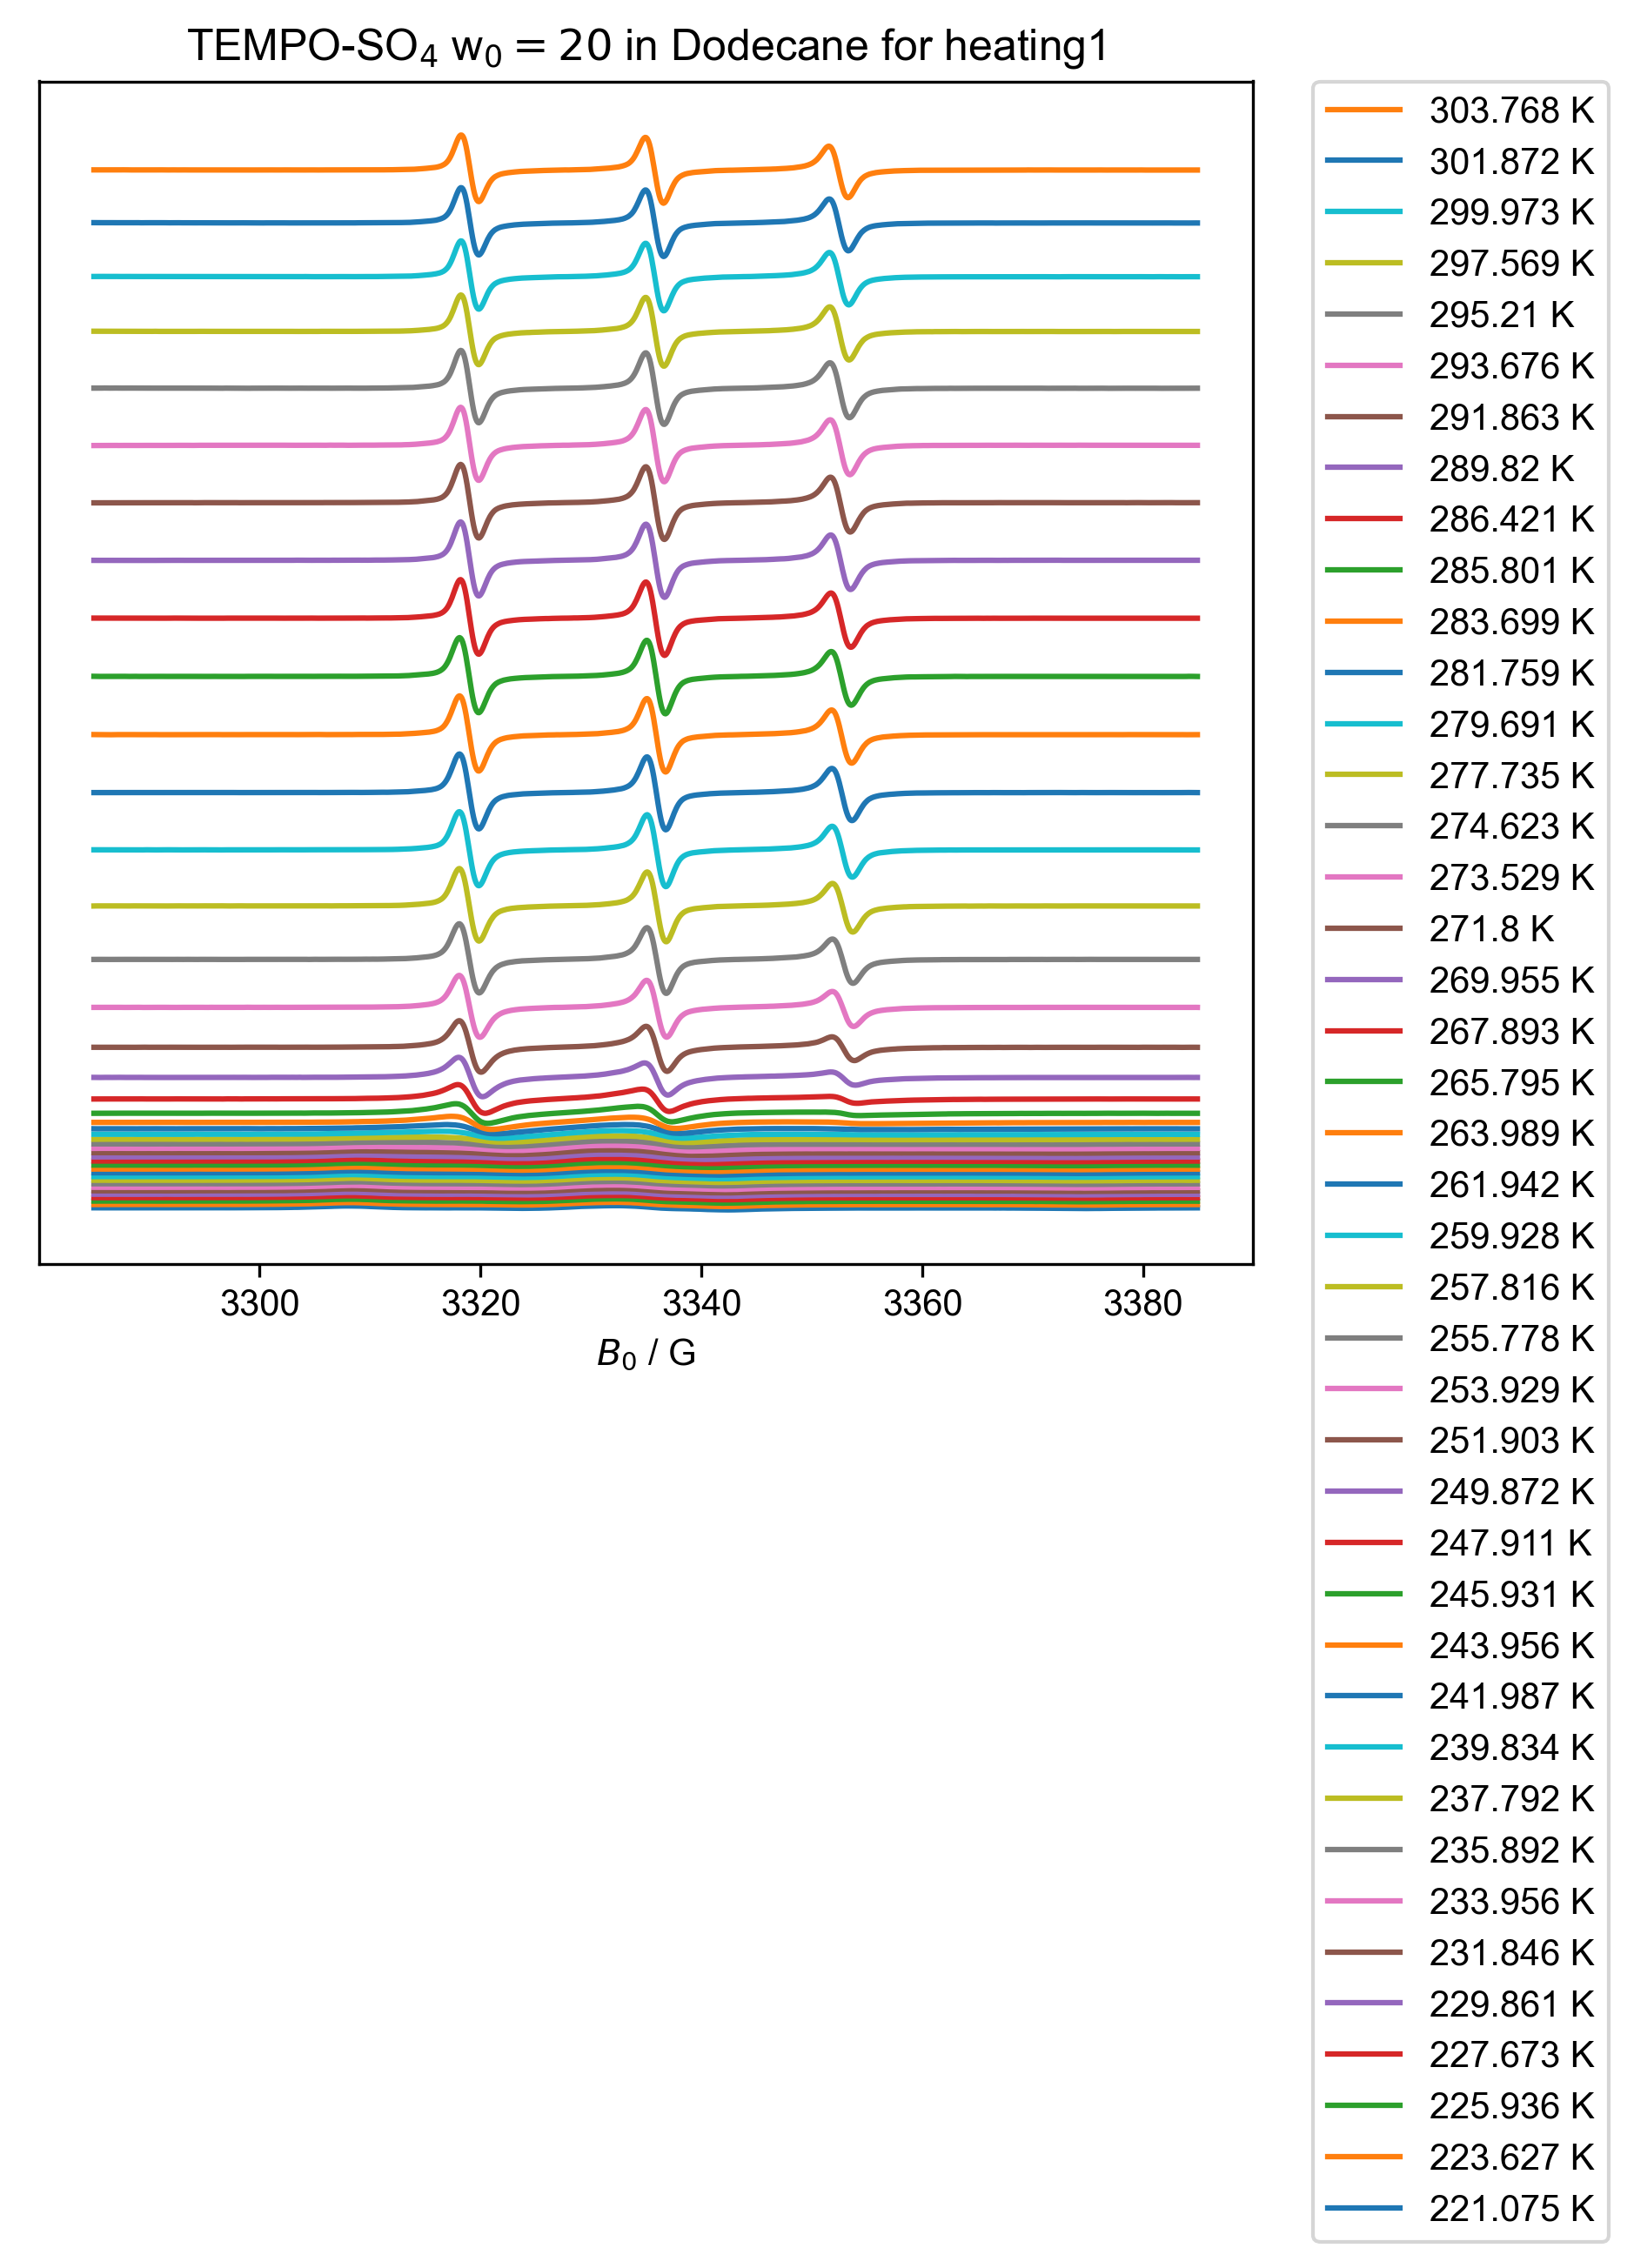

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0=20$ in Dodecane for heating1", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[220.222 222.212 224.388 226.511 228.372 230.042 232.191 234.012 236.139
 238.433 240.336 242.407 244.509 246.334 248.259 250.178 252.315 254.247
 256.278 258.29  260.322 262.087 264.354 266.263 268.242 270.43  272.17
 274.407 276.236 278.472 280.325 282.241 284.054 286.016 288.545 290.073
 292.191 294.192 296.277 299.498 301.773 303.12 ]
[221.075 223.627 225.936 227.673 229.861 231.846 233.956 235.892 237.792
 239.834 241.987 243.956 245.931 247.911 249.872 251.903 253.929 255.778
 257.816 259.928 261.942 263.989 265.795 267.893 269.955 271.8   273.529
 274.623 277.735 279.691 281.759 283.699 285.801 286.421 289.82  291.863
 293.676 295.21  297.569 299.973 301.872 303.768]


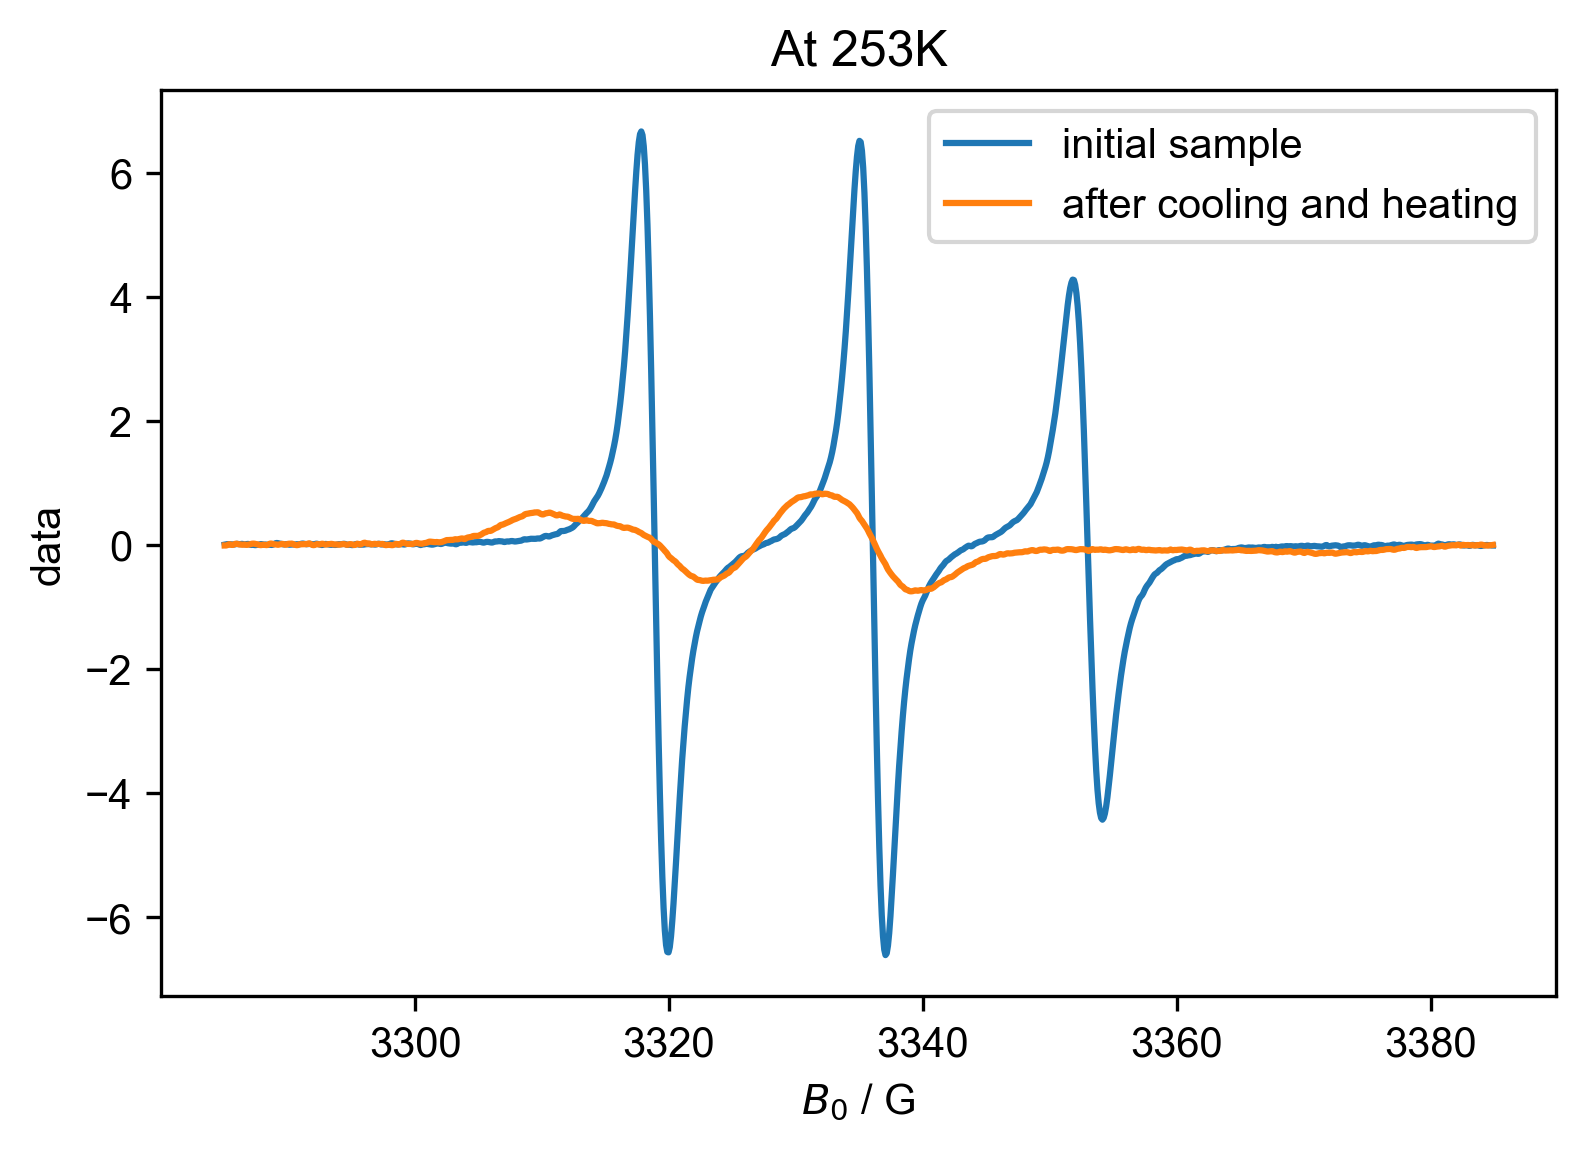

In [50]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[220.222 222.212 224.388 226.511 228.372 230.042 232.191 234.012 236.139
 238.433 240.336 242.407 244.509 246.334 248.259 250.178 252.315 254.247
 256.278 258.29  260.322 262.087 264.354 266.263 268.242 270.43  272.17
 274.407 276.236 278.472 280.325 282.241 284.054 286.016 288.545 290.073
 292.191 294.192 296.277 299.498 301.773 303.12 ]
[221.075 223.627 225.936 227.673 229.861 231.846 233.956 235.892 237.792
 239.834 241.987 243.956 245.931 247.911 249.872 251.903 253.929 255.778
 257.816 259.928 261.942 263.989 265.795 267.893 269.955 271.8   273.529
 274.623 277.735 279.691 281.759 283.699 285.801 286.421 289.82  291.863
 293.676 295.21  297.569 299.973 301.872 303.768]


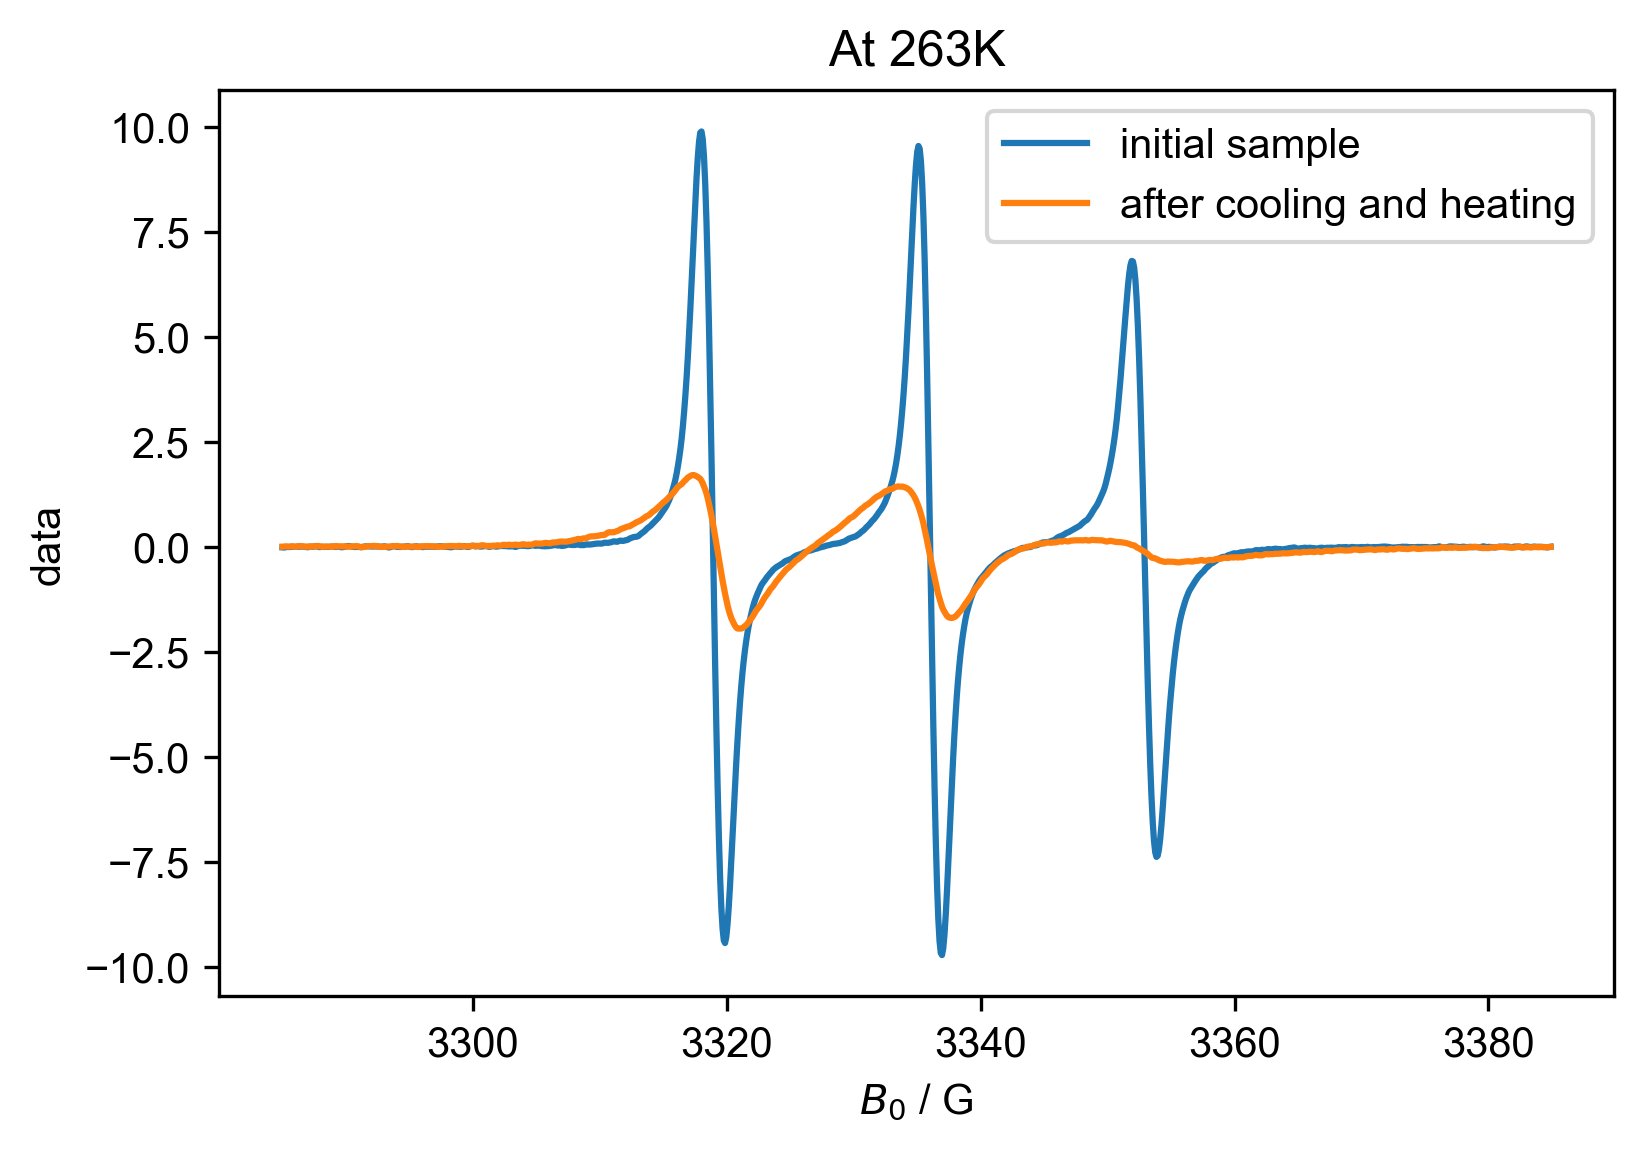

In [51]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="initial sample")
plot(d2["Temperature":263], label="after cooling and heating")
title("At 263K")
legend()

[220.222 222.212 224.388 226.511 228.372 230.042 232.191 234.012 236.139
 238.433 240.336 242.407 244.509 246.334 248.259 250.178 252.315 254.247
 256.278 258.29  260.322 262.087 264.354 266.263 268.242 270.43  272.17
 274.407 276.236 278.472 280.325 282.241 284.054 286.016 288.545 290.073
 292.191 294.192 296.277 299.498 301.773 303.12 ]
[221.075 223.627 225.936 227.673 229.861 231.846 233.956 235.892 237.792
 239.834 241.987 243.956 245.931 247.911 249.872 251.903 253.929 255.778
 257.816 259.928 261.942 263.989 265.795 267.893 269.955 271.8   273.529
 274.623 277.735 279.691 281.759 283.699 285.801 286.421 289.82  291.863
 293.676 295.21  297.569 299.973 301.872 303.768]


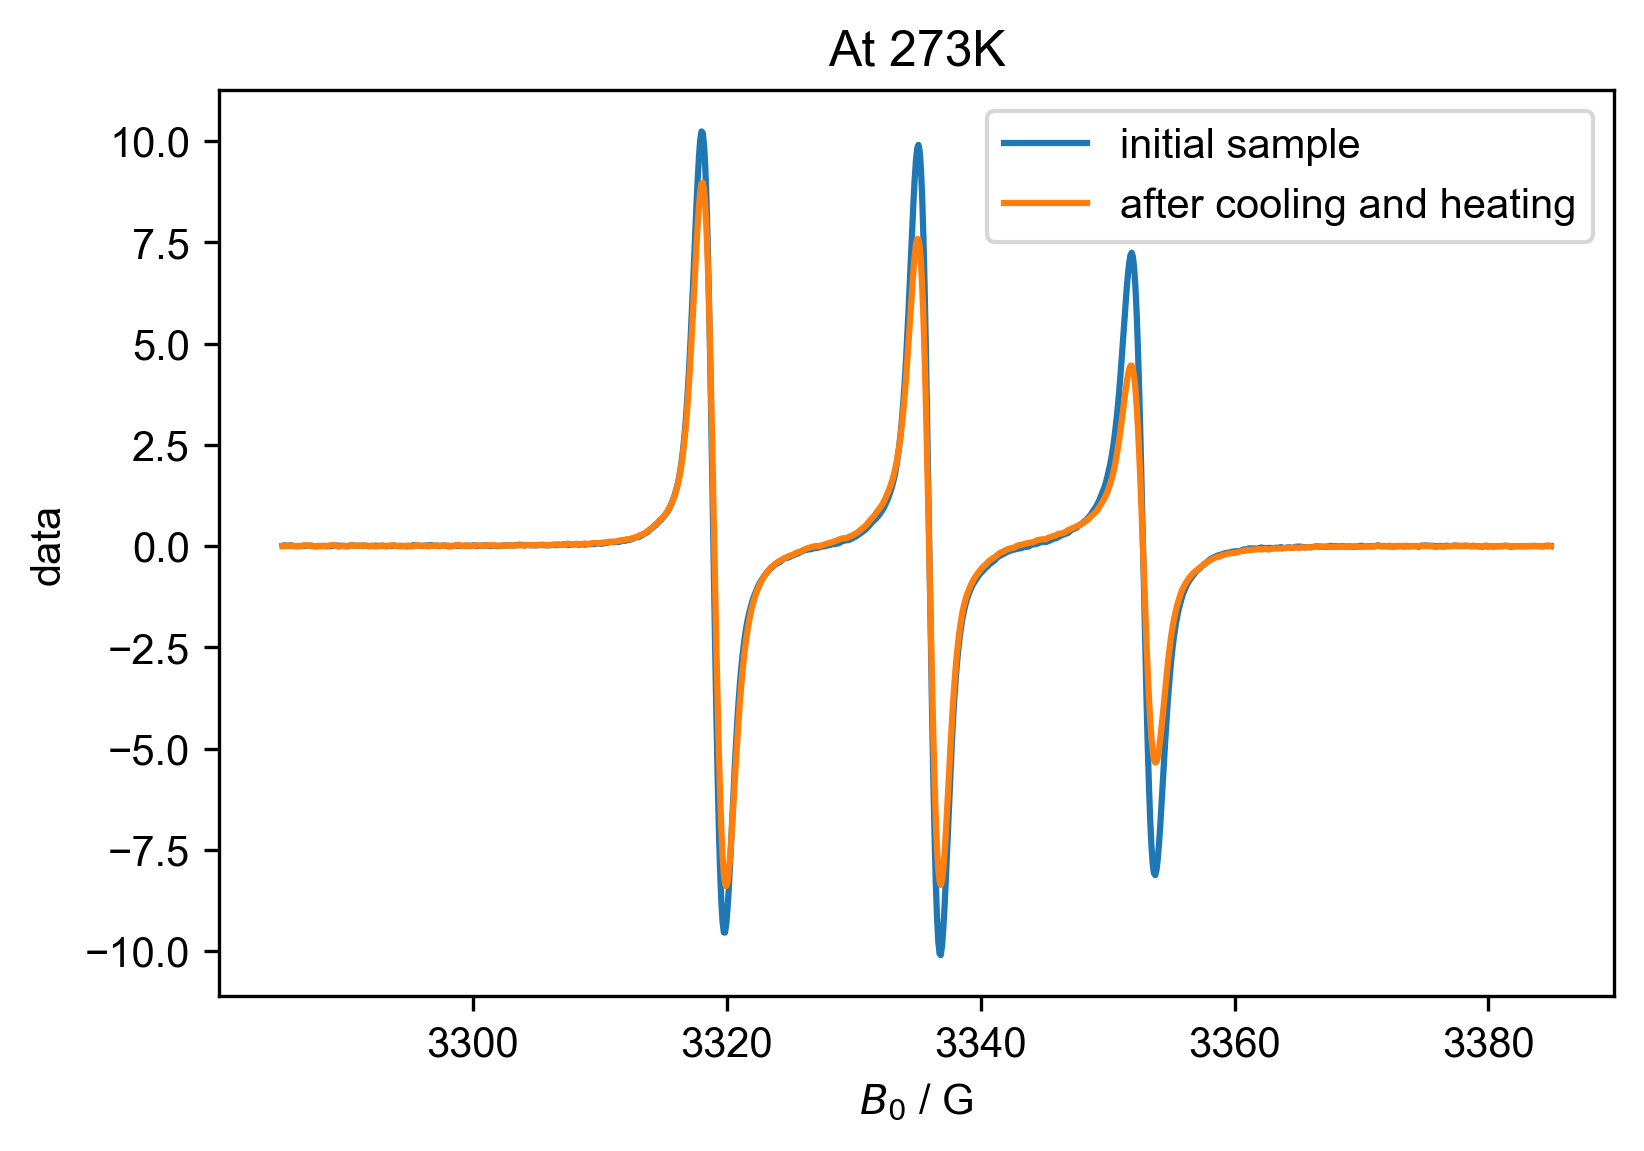

In [52]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[220.222 222.212 224.388 226.511 228.372 230.042 232.191 234.012 236.139
 238.433 240.336 242.407 244.509 246.334 248.259 250.178 252.315 254.247
 256.278 258.29  260.322 262.087 264.354 266.263 268.242 270.43  272.17
 274.407 276.236 278.472 280.325 282.241 284.054 286.016 288.545 290.073
 292.191 294.192 296.277 299.498 301.773 303.12 ]
[221.075 223.627 225.936 227.673 229.861 231.846 233.956 235.892 237.792
 239.834 241.987 243.956 245.931 247.911 249.872 251.903 253.929 255.778
 257.816 259.928 261.942 263.989 265.795 267.893 269.955 271.8   273.529
 274.623 277.735 279.691 281.759 283.699 285.801 286.421 289.82  291.863
 293.676 295.21  297.569 299.973 301.872 303.768]


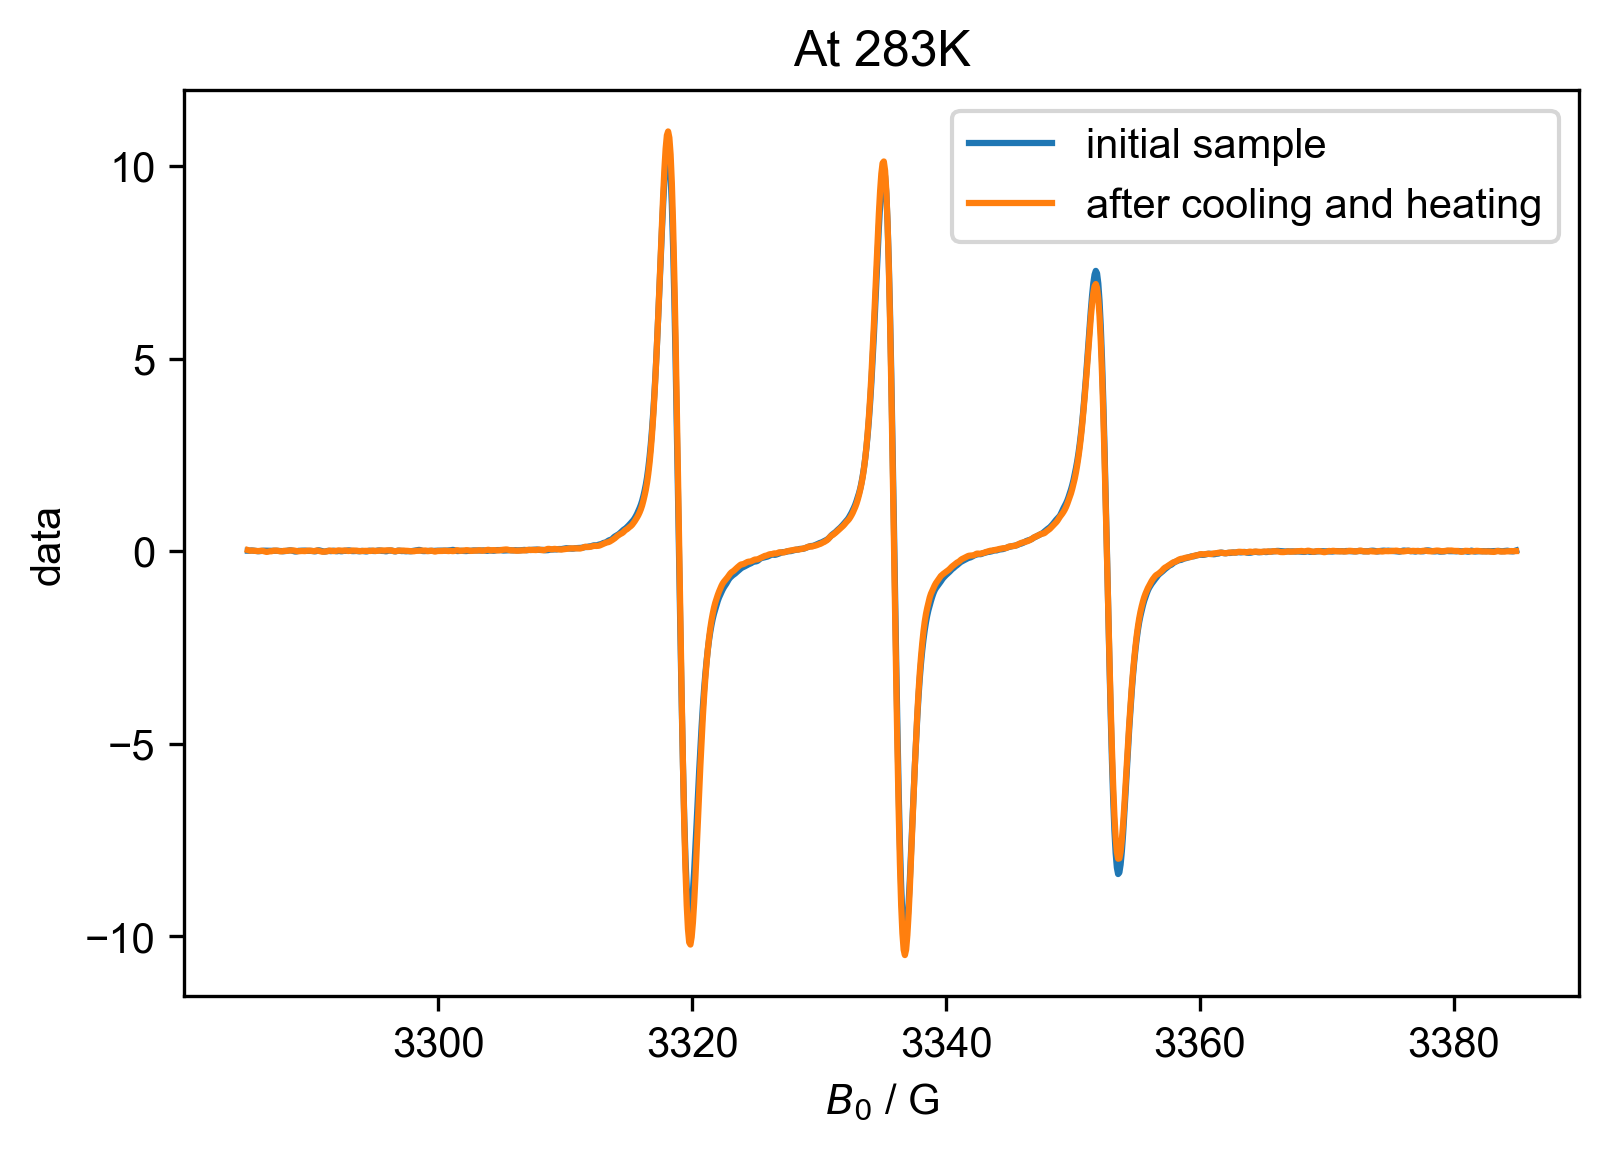

In [53]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

In [54]:
# #Normalized
# figure(dpi=300, figsize=(7,4))
# plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
# plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
# title("Normalized TEMPO-SO$_4$ w$_0= 20$ in Dodecane near room temperature (283K)")
# legend()